# 미국 TSA 보안검색 통과자 수 분석 (2019~2026)

데이터: `collect_data.py`로 tsa.gov에서 수집한 일별 통과자 수

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

plt.rcParams['font.family'] = 'AppleGothic'  # 한글 깨짐 방지 (mac)
plt.rcParams['axes.unicode_minus'] = False

# 설정
DATA_PATH = 'data/tsa_daily.csv'
DATE_COL = 'date'
VALUE_COL = 'passengers'

# 세로축을 '백만 명' 단위로 표시 (1e6 표기 대신)
MILLION = FuncFormatter(lambda x, _: f'{x/1e6:.1f}')

## 1. 데이터 불러오기 · 기본 정보

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=[DATE_COL])
df = df.sort_values(DATE_COL).set_index(DATE_COL)
print(df.shape)
print(df.index.min(), '~', df.index.max())
df.info()
df.head()

(2835, 1)
2019-01-01 00:00:00 ~ 2026-10-05 00:00:00
<class 'pandas.DataFrame'>
DatetimeIndex: 2835 entries, 2019-01-01 to 2026-10-05
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   passengers  2835 non-null   int64
dtypes: int64(1)
memory usage: 44.3 KB


,passengers
date,
2019-01-01,2201765
2019-01-02,2424225
2019-01-03,2279384
2019-01-04,2230078
2019-01-05,2049460


## 2. 정제: 결측치 · 중복 · 이상치

In [3]:
print('결측치:\n', df.isna().sum())
print('중복 날짜:', df.index.duplicated().sum())
df[VALUE_COL].describe()

결측치:
 passengers    0
dtype: int64
중복 날짜: 0


count    2.835000e+03
mean     2.077104e+06
std      6.506654e+05
min      1.131470e+05
25%      1.879716e+06
50%      2.224826e+06
75%      2.541850e+06
max      3.134613e+06
Name: passengers, dtype: float64

In [4]:
# 이상치 확인 (IQR 기준)
q1, q3 = df[VALUE_COL].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df[VALUE_COL] < q1 - 1.5*iqr) | (df[VALUE_COL] > q3 + 1.5*iqr)]
print('이상치 개수:', len(outliers))
print('기간:', outliers.index.min().date(), '~', outliers.index.max().date())

이상치 개수: 274
기간: 2020-03-18 ~ 2021-03-09


IQR로는 코로나 기간만 걸림 → 요일 패턴을 반영한 기준을 따로 만듦

- 기준값: 같은 요일의 최근 4주 중앙값 (당일 제외)
- 이 기준보다 ±25% 넘게 벗어나면 이상치로 표시 (2022년 이후)
- 지우지 않고 이벤트로 해석

In [5]:
baseline = df[VALUE_COL].groupby(df.index.dayofweek).transform(lambda x: x.shift(1).rolling(4).median())
df['dev_pct'] = (df[VALUE_COL] / baseline - 1) * 100
unusual = df.loc['2022':, 'dev_pct']
unusual = unusual[unusual.abs() > 25].round(1)
print('±25% 넘게 벗어난 날:', len(unusual))
print(unusual.sort_values().head(10))
print(unusual.sort_values().tail(5))

±25% 넘게 벗어난 날: 52
date
2026-01-25   -49.8
2023-11-23   -40.3
2024-11-28   -39.3
2022-01-11   -38.4
2025-11-27   -38.0
2022-11-24   -37.5
2022-01-12   -35.0
2022-01-19   -31.9
2026-01-13   -30.6
2026-01-24   -29.8
Name: dev_pct, dtype: float64
date
2022-02-16    39.1
2024-11-26    39.4
2022-02-18    39.5
2022-02-21    41.9
2022-02-22    46.2
Name: dev_pct, dtype: float64


## 3. 시계열 분석 기법 (최소 2가지)

In [6]:
df['ma_7'] = df[VALUE_COL].rolling(7).mean()
df['ma_30'] = df[VALUE_COL].rolling(30).mean()
df['pct_change'] = df[VALUE_COL].pct_change() * 100
# 전년 같은 요일 대비 변화율 (364일 = 52주 전)
df['yoy_pct'] = (df[VALUE_COL] / df[VALUE_COL].shift(364) - 1) * 100
df['weekday'] = df.index.day_name()
monthly = df[VALUE_COL].resample('MS').mean()
monthly.tail()

date
2026-06-01    2.691045e+06
2026-07-01    2.688392e+06
2026-08-01    2.477173e+06
2026-09-01    2.353904e+06
2026-10-01    2.572682e+06
Freq: MS, Name: passengers, dtype: float64

## 4. 시각화

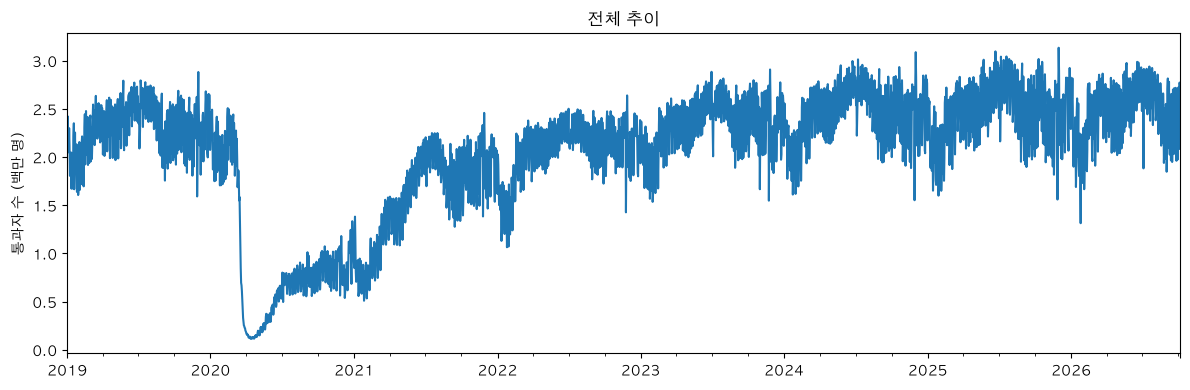

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
df[VALUE_COL].plot(ax=ax)
ax.set_title('전체 추이')
ax.yaxis.set_major_formatter(MILLION)
ax.set_ylabel('통과자 수 (백만 명)'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('images/01_trend.png', dpi=150); plt.show()

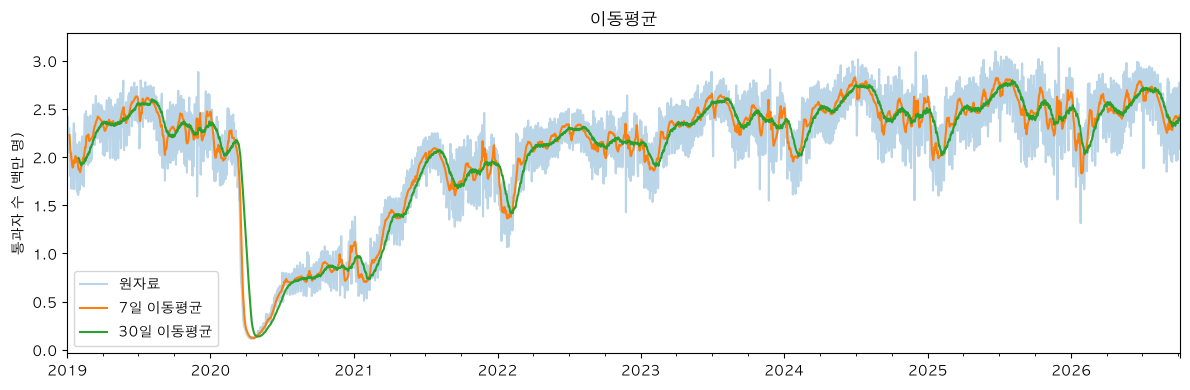

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
df[VALUE_COL].plot(ax=ax, alpha=0.3, label='원자료')
df['ma_7'].plot(ax=ax, label='7일 이동평균')
df['ma_30'].plot(ax=ax, label='30일 이동평균')
ax.set_title('이동평균'); ax.legend()
ax.yaxis.set_major_formatter(MILLION)
ax.set_ylabel('통과자 수 (백만 명)'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('images/02_moving_average.png', dpi=150); plt.show()

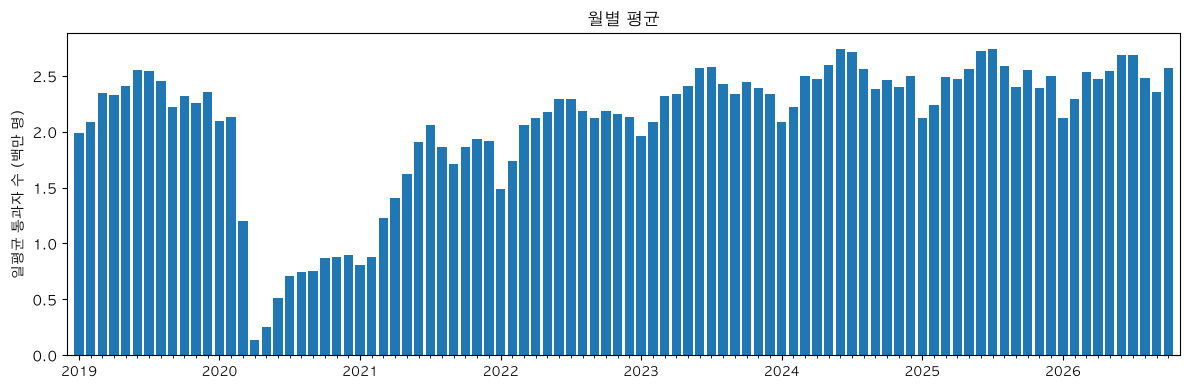

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(monthly)), monthly.values / 1e6, color='tab:blue')
# 1월에만 연도 표시 (94개월을 다 쓰면 겹침)
jan = [i for i, d in enumerate(monthly.index) if d.month == 1]
ax.set_xticks(jan)
ax.set_xticklabels([monthly.index[i].year for i in jan], fontsize=9)
ax.set_xticks(range(len(monthly)), minor=True)
ax.set_xlim(-1, len(monthly))
ax.set_ylabel('일평균 통과자 수 (백만 명)')
ax.set_title('월별 평균')
plt.tight_layout(); plt.savefig('images/03_monthly.png', dpi=150); plt.show()

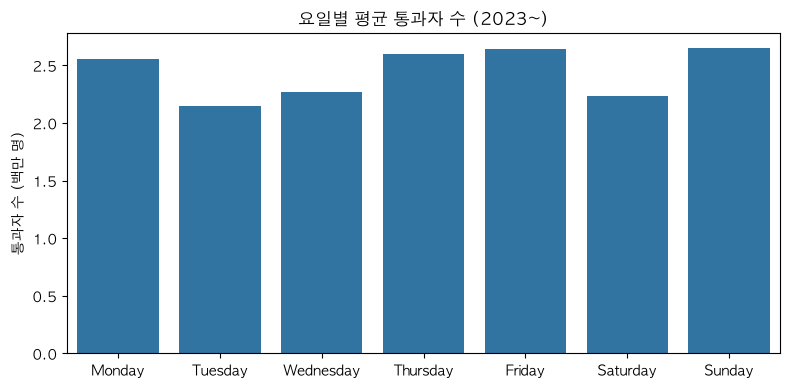

In [10]:
# 요일별 평균 (2023년 이후, 코로나 영향 제외)
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
recent = df[df.index >= '2023-01-01']
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x='weekday', y=VALUE_COL, data=recent, order=order, ax=ax, errorbar=None)
ax.set_title('요일별 평균 통과자 수 (2023~)')
ax.yaxis.set_major_formatter(MILLION)
ax.set_ylabel('통과자 수 (백만 명)'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('images/04_weekday.png', dpi=150); plt.show()

In [11]:
# 가장 붐빈 날 / 가장 한산한 날 Top 5
print(df[VALUE_COL].nlargest(5))
print(df[df.index >= '2021-01-01'][VALUE_COL].nsmallest(5))

date
2025-11-30    3134613
2025-06-22    3096797
2024-12-01    3088836
2025-07-20    3043973
2025-07-06    3041954
Name: passengers, dtype: int64
date
2021-01-26    508467
2021-02-02    532690
2021-01-12    557517
2021-01-27    574099
2021-01-20    581771
Name: passengers, dtype: int64


## 6. 보너스: 시계열 분해 · 간단 예측

### (A) 시계열 분해

월평균(2022-01 ~ 2026-09)을 추세 + 계절성(12개월) + 나머지로 나눔.
코로나 급락 구간(2020~2021)은 추세를 왜곡해서 제외, 데이터가 며칠만 있는 2026-10도 제외.

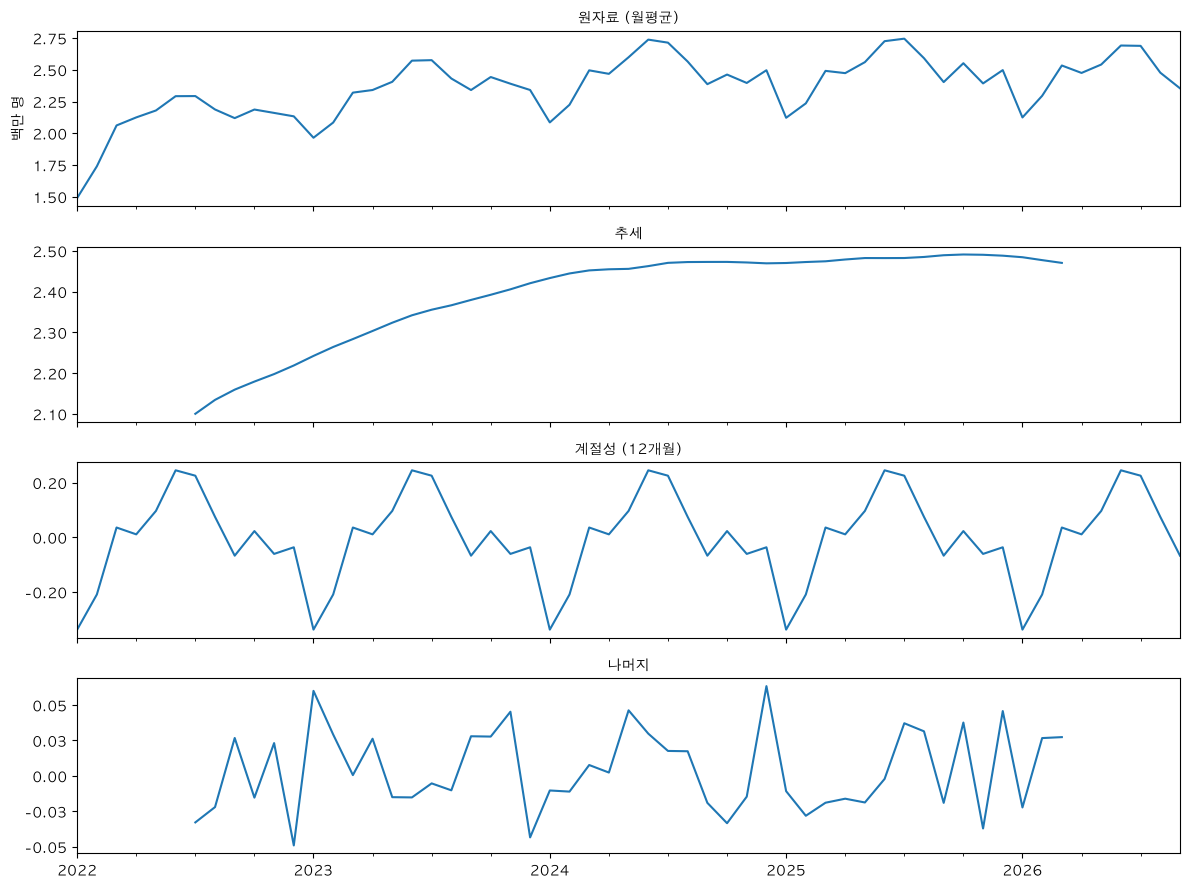

월별 계절 효과 (만 명):
date
1    -34
2    -21
9     -7
11    -6
12    -4
4      1
10     2
3      4
8      7
5     10
7     23
6     25
Name: seasonal, dtype: int64


In [12]:
from statsmodels.tsa.seasonal import seasonal_decompose

m = monthly['2022-01':'2026-09']
MILLION2 = FuncFormatter(lambda x, _: f'{x/1e6:.2f}')  # 나머지 값이 작아서 소수 둘째 자리까지
decomp = seasonal_decompose(m, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (part, title) in zip(axes, [(decomp.observed, '원자료 (월평균)'), (decomp.trend, '추세'),
                                    (decomp.seasonal, '계절성 (12개월)'), (decomp.resid, '나머지')]):
    part.plot(ax=ax)
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_major_formatter(MILLION2)
    ax.set_xlabel('')
axes[0].set_ylabel('백만 명')
plt.tight_layout(); plt.savefig('images/05_decompose.png', dpi=150); plt.show()

# 계절성: 월별로 평균보다 얼마나 많은지/적은지
season = (decomp.seasonal[:12] / 1e4).round().astype(int)
season.index = season.index.month
print('월별 계절 효과 (만 명):')
print(season.sort_values())

### (B) 간단 예측 (베이스라인)

마지막 4주(28일)를 정답으로 숨기고, 그 이전 데이터만으로 예측해서 비교.

- 방법 1. **작년 같은 요일 그대로**: 364일 전 값을 그대로 씀
- 방법 2. **작년 같은 요일 × 최근 성장률**: 예측 직전 4주가 작년 같은 기간보다 몇 % 많았는지를 곱함

정확도보다 가정과 한계를 보는 게 목적.

최근 성장률: -3.3%
방법 1 오차(MAPE): 3.9%
방법 2 오차(MAPE): 3.1%


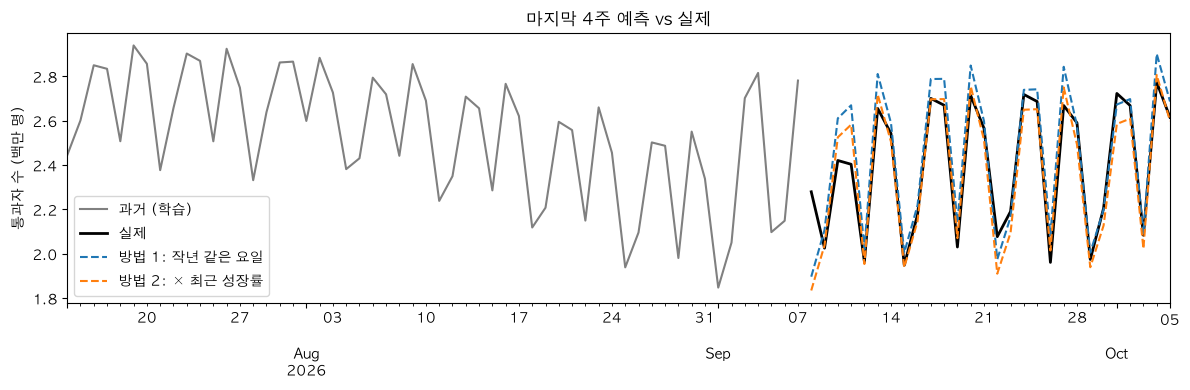

In [13]:
H = 28
train, test = df[VALUE_COL][:-H], df[VALUE_COL][-H:]

last_year = df[VALUE_COL].shift(364)
pred1 = last_year[-H:]

# 예측 직전 4주의 전년 대비 비율
recent = train[-28:]
growth = recent.sum() / last_year[recent.index].sum()
pred2 = pred1 * growth

def mape(actual, pred):
    return (abs(actual - pred) / actual).mean() * 100

print(f'최근 성장률: {(growth - 1) * 100:+.1f}%')
print(f'방법 1 오차(MAPE): {mape(test, pred1):.1f}%')
print(f'방법 2 오차(MAPE): {mape(test, pred2):.1f}%')

fig, ax = plt.subplots(figsize=(12, 4))
train[-56:].plot(ax=ax, color='gray', label='과거 (학습)')
test.plot(ax=ax, color='black', linewidth=2, label='실제')
pred1.plot(ax=ax, linestyle='--', label='방법 1: 작년 같은 요일')
pred2.plot(ax=ax, linestyle='--', label='방법 2: × 최근 성장률')
ax.yaxis.set_major_formatter(MILLION)
ax.set_ylabel('통과자 수 (백만 명)'); ax.set_xlabel('')
ax.set_title('마지막 4주 예측 vs 실제'); ax.legend()
plt.tight_layout(); plt.savefig('images/06_forecast.png', dpi=150); plt.show()

## 5. 메모 (관찰 / 해석)

- 관찰:
- 해석: